# Análise de defeitos de manufatura
**Hipótese:** lotes com mais horas de manutenção (`MaintenanceHours`) têm maior probabilidade de defeito (`DefectStatus = 1`).

Roteiro: 1) configuração → 2) exploração → 3) triagem de variáveis e hipóteses candidatas → 4) pressupostos → 5) teste principal → 6) robustez → 7) forma da relação (limiar) → 8) conclusão.

> Análise **observacional**: os resultados indicam associação, não causalidade.

## 1. Configuração

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from scipy import stats

# Procura o CSV na pasta do notebook (Colab) ou na pasta acima (Downloads)
NOME = "manufacturing_defect_dataset.csv"
CSV = next((p for p in [Path(NOME), Path("..") / NOME] if p.exists()), None)
assert CSV is not None, f"Coloque {NOME} na mesma pasta do notebook"

ALPHA = 0.05
TARGET = "DefectStatus"
VAR = "MaintenanceHours"
LEAKY = ["DefectRate", "QualityScore"]  # provavelmente medem o próprio resultado de qualidade
rng = np.random.default_rng(42)

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200, "display.max_columns", 30)
print("Lendo:", CSV.resolve())

Lendo: C:\Users\Aluno GC.CAMPUS-07\Downloads\manufacturing_defect_dataset.csv


## 2. Exploração dos dados

In [2]:
df = pd.read_csv(CSV)
print(f"{df.shape[0]} linhas x {df.shape[1]} colunas")
print("Nulos:", df.isna().sum().sum(), "| Duplicatas:", df.duplicated().sum())
df.head(10)

3240 linhas x 17 colunas
Nulos: 0 | Duplicatas: 0


,ProductionVolume,ProductionCost,SupplierQuality,DeliveryDelay,DefectRate,QualityScore,MaintenanceHours,DowntimePercentage,InventoryTurnover,StockoutRate,WorkerProductivity,SafetyIncidents,EnergyConsumption,EnergyEfficiency,AdditiveProcessTime,AdditiveMaterialCost,DefectStatus
0,202,13175.403783,86.648534,1,3.121492,63.463494,9,0.052343,8.630515,0.081322,85.042379,0,2419.616785,0.468947,5.551639,236.439301,1
1,535,19770.046093,86.310664,4,0.819531,83.697818,20,4.908328,9.296598,0.038486,99.657443,7,3915.566713,0.119485,9.080754,353.957631,1
2,960,19060.820997,82.132472,0,4.514504,90.350550,1,2.464923,5.097486,0.002887,92.819264,2,3392.385362,0.496392,6.562827,396.189402,1
3,370,5647.606037,87.335966,5,0.638524,67.628690,8,4.692476,3.577616,0.055331,96.887013,8,4652.400275,0.183125,8.097496,164.135870,1
4,206,7472.222236,81.989893,3,3.867784,82.728334,9,2.746726,6.851709,0.068047,88.315554,7,1581.630332,0.263507,6.406154,365.708964,1
5,171,6975.931602,95.331919,1,3.914574,92.568436,19,3.027324,7.930009,0.074069,87.079118,7,1238.994421,0.118021,7.279442,171.711804,1
6,800,15889.698650,99.325486,3,4.789000,90.729911,10,3.559561,3.046889,0.040192,91.063158,8,3138.431150,0.333913,4.891669,188.727737,1
7,120,17266.779948,99.401489,4,0.743605,92.119681,13,1.604879,8.380972,0.009702,88.705569,3,1004.108554,0.293422,9.333835,312.526896,1
8,714,8202.670495,97.301422,5,3.185856,95.172937,2,3.494920,3.668747,0.058433,94.298961,4,4150.875773,0.366683,5.517451,215.680921,1
9,221,12587.790394,92.015843,2,2.425283,97.507284,0,2.633960,5.933418,0.032955,85.316362,6,3023.891555,0.317071,5.965972,364.638176,0


In [3]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
ProductionVolume,3240.0,548.52,262.40,100.00,322.00,549.00,775.25,999.00
ProductionCost,3240.0,12423.02,4308.05,5000.17,8728.83,12405.20,16124.46,19993.37
SupplierQuality,3240.0,89.83,5.76,80.00,84.87,89.70,94.79,99.99
DeliveryDelay,3240.0,2.56,1.71,0.00,1.00,3.00,4.00,5.00
DefectRate,3240.0,2.75,1.31,0.50,1.60,2.71,3.90,5.00
QualityScore,3240.0,80.13,11.61,60.01,70.10,80.27,90.35,100.00
MaintenanceHours,3240.0,11.48,6.87,0.00,5.75,12.00,17.00,23.00
DowntimePercentage,3240.0,2.50,1.44,0.00,1.26,2.47,3.77,5.00
InventoryTurnover,3240.0,6.02,2.33,2.00,3.98,6.02,8.05,10.00
StockoutRate,3240.0,0.05,0.03,0.00,0.03,0.05,0.08,0.10


,n,%
DefectStatus,,
Com defeito,2723,84.0
Sem defeito,517,16.0


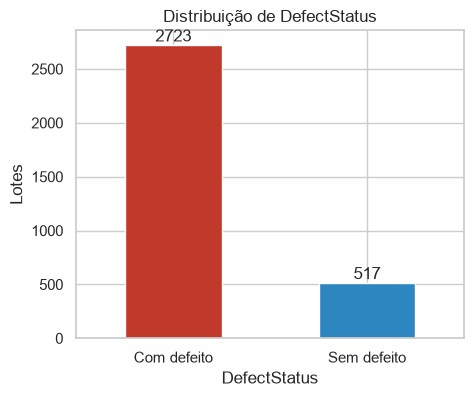

In [4]:
contagem = df[TARGET].value_counts().rename({0: "Sem defeito", 1: "Com defeito"})
display(pd.DataFrame({"n": contagem, "%": (contagem / len(df) * 100).round(1)}))

ax = contagem.plot.bar(color=["#c0392b", "#2e86c1"], figsize=(5, 4), rot=0)
ax.set_title("Distribuição de DefectStatus"); ax.set_ylabel("Lotes")
for p in ax.patches:
    ax.annotate(f"{p.get_height():.0f}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
plt.show()

O alvo é desbalanceado: **84% dos lotes têm defeito**. As variáveis têm distribuição quase uniforme, típica de dados sintéticos.

## 3. Triagem de variáveis e hipóteses candidatas

In [5]:
rows = []
for c in df.columns.drop(TARGET):
    g1, g0 = df.loc[df[TARGET] == 1, c], df.loc[df[TARGET] == 0, c]
    rows.append({
        "variavel": c,
        "spearman_alvo": df[c].corr(df[TARGET], method="spearman"),
        "mediana_defeito": g1.median(),
        "mediana_ok": g0.median(),
        "p_mannwhitney": stats.mannwhitneyu(g1, g0).pvalue,
        "possivel_leakage": c in LEAKY,
    })
triagem = pd.DataFrame(rows).sort_values("p_mannwhitney").reset_index(drop=True)
triagem.round(4)

,variavel,spearman_alvo,mediana_defeito,mediana_ok,p_mannwhitney,possivel_leakage
0,MaintenanceHours,0.2971,13.0000,6.0000,0.0000,False
1,DefectRate,0.2444,3.0273,1.9776,0.0000,True
2,QualityScore,-0.1986,78.5748,85.8639,0.0000,True
3,ProductionVolume,0.1296,565.0000,469.0000,0.0000,False
4,StockoutRate,0.0400,0.0523,0.0477,0.0228,False
5,SupplierQuality,0.0386,89.8606,88.8246,0.0280,False
6,EnergyEfficiency,-0.0351,0.2953,0.3146,0.0459,False
7,ProductionCost,0.0269,12505.3917,12035.6112,0.1257,False
8,SafetyIncidents,-0.0160,5.0000,5.0000,0.3613,False
9,InventoryTurnover,0.0066,6.0289,5.9428,0.7062,False


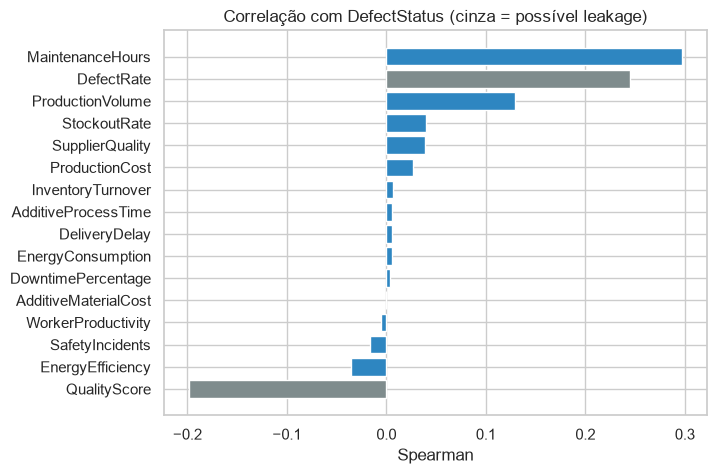

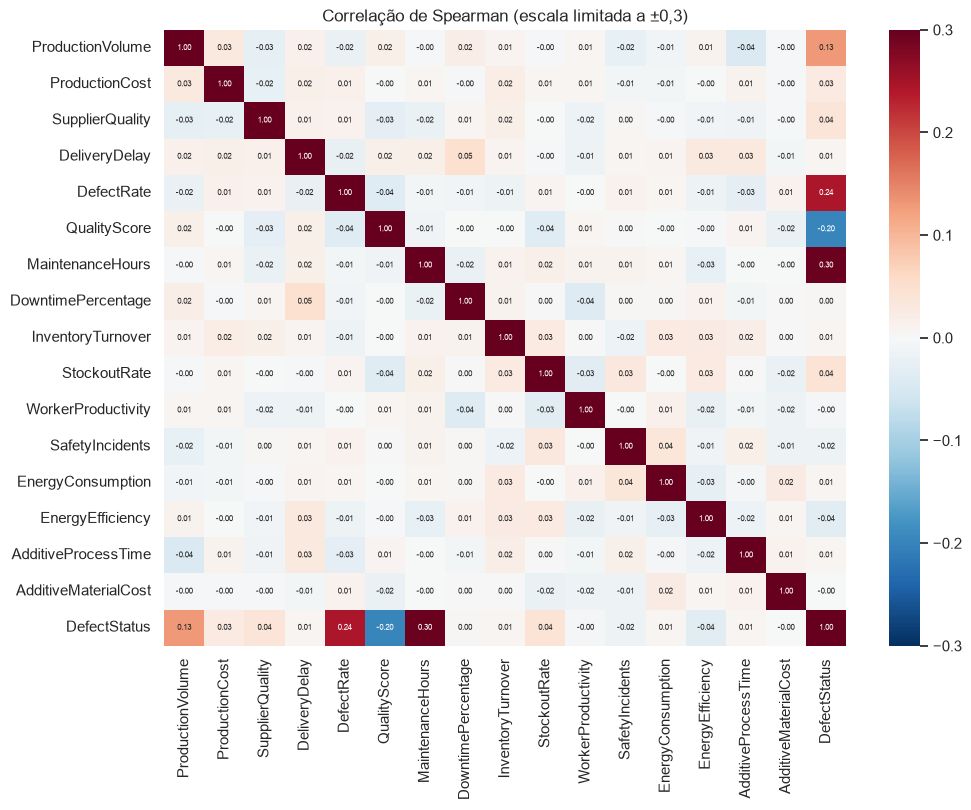

In [6]:
t = triagem.sort_values("spearman_alvo")
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(t["variavel"], t["spearman_alvo"], color=["#7f8c8d" if l else "#2e86c1" for l in t["possivel_leakage"]])
ax.set_title("Correlação com DefectStatus (cinza = possível leakage)"); ax.set_xlabel("Spearman")
plt.show()

fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(df.corr(method="spearman"), cmap="RdBu_r", center=0, vmin=-0.3, vmax=0.3, annot=True, fmt=".2f",
            annot_kws={"size": 6}, ax=ax)
ax.set_title("Correlação de Spearman (escala limitada a ±0,3)")
plt.show()

**Hipóteses candidatas**
1. **Horas de manutenção:** mais horas de manutenção estão associadas a maior chance de defeito. É o sinal mais forte sem risco de leakage (ρ ≈ 0,30). ← **escolhida**
2. **Volume de produção:** lotes maiores estão associados a maior chance de defeito (ρ ≈ 0,13).
3. **Qualidade do fornecedor:** o efeito é desprezível (ρ ≈ 0,04) e vai no sentido oposto ao esperado.

`DefectRate` e `QualityScore` ficaram de fora porque provavelmente são medidas do próprio resultado de qualidade (leakage).

**Hipótese formal**
- **H0:** a distribuição de `MaintenanceHours` é igual em lotes com e sem defeito.
- **H1:** lotes com defeito tendem a ter mais horas de manutenção (teste unilateral).
- **α = 0,05**

## 4. Pressupostos

,verificação,p-valor
0,"Shapiro-Wilk, defeito (amostra de 500)",3.819201e-12
1,"Shapiro-Wilk, sem defeito (amostra de 500)",1.126426e-15
2,Levene (variâncias),6.168815e-27


MaintenanceHours: variável discreta com 24 valores | n defeito = 2723, n sem defeito = 517


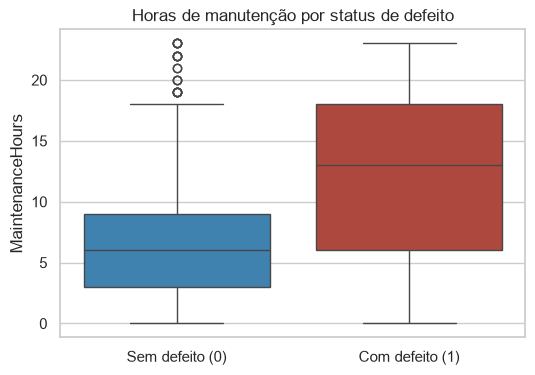

In [7]:
g1 = df.loc[df[TARGET] == 1, VAR].to_numpy()
g0 = df.loc[df[TARGET] == 0, VAR].to_numpy()

pressupostos = pd.DataFrame({
    "verificação": ["Shapiro-Wilk, defeito (amostra de 500)", "Shapiro-Wilk, sem defeito (amostra de 500)", "Levene (variâncias)"],
    "p-valor": [stats.shapiro(rng.choice(g1, 500, replace=False)).pvalue,
                stats.shapiro(rng.choice(g0, 500, replace=False)).pvalue,
                stats.levene(g1, g0).pvalue],
})
display(pressupostos)
print(f"{VAR}: variável discreta com {df[VAR].nunique()} valores | n defeito = {len(g1)}, n sem defeito = {len(g0)}")

fig, ax = plt.subplots(figsize=(6, 4))
sns.boxplot(data=df, x=TARGET, y=VAR, hue=TARGET, palette=["#2e86c1", "#c0392b"], legend=False, ax=ax)
ax.set_xticks([0, 1], ["Sem defeito (0)", "Com defeito (1)"]); ax.set_xlabel("")
ax.set_title("Horas de manutenção por status de defeito")
plt.show()

A normalidade é rejeitada e as variâncias são diferentes, o que descarta o teste t como teste principal. Por isso o teste principal é **Mann-Whitney U**, lido como dominância estocástica.

## 5. Teste principal: Mann-Whitney U

In [8]:
mw = stats.mannwhitneyu(g1, g0, alternative="greater")

def rank_biserial(a, b):
    return 2 * stats.mannwhitneyu(a, b).statistic / (len(a) * len(b)) - 1

rb = rank_biserial(g1, g0)
boot = [rank_biserial(rng.choice(g1, len(g1)), rng.choice(g0, len(g0))) for _ in range(2000)]
ic = np.percentile(boot, [2.5, 97.5])

print(f"U = {mw.statistic:,.1f}   p = {mw.pvalue:.2e}")
print(f"Mediana: defeito = {np.median(g1):.0f} h | sem defeito = {np.median(g0):.0f} h")
print(f"Rank-biserial = {rb:.3f}  (IC 95% bootstrap: {ic[0]:.3f} a {ic[1]:.3f})")
print(f"P(lote com defeito tem mais horas que lote sem defeito) = {(rb + 1) / 2:.1%}")
print("Decisão:", "rejeitar H0" if mw.pvalue < ALPHA else "não rejeitar H0")

U = 1,033,362.5   p = 1.86e-64
Mediana: defeito = 13 h | sem defeito = 6 h
Rank-biserial = 0.468  (IC 95% bootstrap: 0.428 a 0.508)
P(lote com defeito tem mais horas que lote sem defeito) = 73.4%
Decisão: rejeitar H0


## 6. Robustez: t de Welch e regressão logística ajustada

In [9]:
w = stats.ttest_ind(g1, g0, equal_var=False, alternative="greater")
print(f"Welch: t = {w.statistic:.2f}, p = {w.pvalue:.2e} | médias {g1.mean():.2f} h x {g0.mean():.2f} h")

X_cols = [c for c in df.columns if c not in LEAKY + [TARGET]]
Xz = (df[X_cols] - df[X_cols].mean()) / df[X_cols].std()
Xz[VAR] = df[VAR]  # manter em horas para interpretar a OR por +1 h
logit = sm.Logit(df[TARGET], sm.add_constant(Xz)).fit(disp=0)
ci = logit.conf_int()
or_tab = pd.DataFrame({"OR": np.exp(logit.params), "IC95_inf": np.exp(ci[0]), "IC95_sup": np.exp(ci[1]),
                       "p": logit.pvalues}).round(4)
print(f"Pseudo-R² = {logit.prsquared:.3f}")
or_tab

Welch: t = 21.50, p = 1.86e-83 | médias 12.37 h x 6.79 h
Pseudo-R² = 0.135


,OR,IC95_inf,IC95_sup,p
const,1.5393,1.3061,1.8142,0.0000
ProductionVolume,1.5049,1.3571,1.6688,0.0000
ProductionCost,1.0642,0.9616,1.1778,0.2288
SupplierQuality,1.1482,1.0385,1.2694,0.0070
DeliveryDelay,1.0040,0.9082,1.1099,0.9374
MaintenanceHours,1.1468,1.1276,1.1663,0.0000
DowntimePercentage,1.0201,0.9225,1.1281,0.6980
InventoryTurnover,0.9968,0.9006,1.1033,0.9512
StockoutRate,1.1111,1.0054,1.2279,0.0388
WorkerProductivity,0.9786,0.8850,1.0821,0.6733


## 7. Forma da relação: existe um limiar?

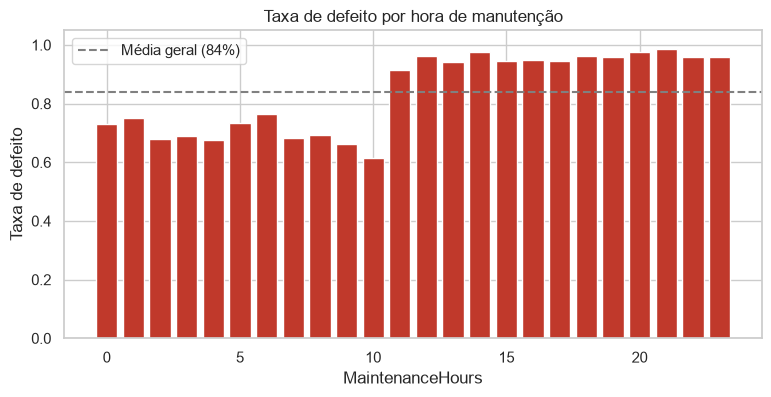

In [10]:
by_hour = df.groupby(VAR)[TARGET].agg(taxa="mean", n="size")
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(by_hour.index, by_hour["taxa"], color="#c0392b")
ax.axhline(df[TARGET].mean(), ls="--", color="gray", label=f"Média geral ({df[TARGET].mean():.0%})")
ax.set_xlabel(VAR); ax.set_ylabel("Taxa de defeito"); ax.set_ylim(0, 1.05)
ax.set_title("Taxa de defeito por hora de manutenção"); ax.legend()
plt.show()

In [11]:
alto = df[VAR] > 10
chi2, p_chi, _, _ = stats.chi2_contingency(pd.crosstab(alto, df[TARGET]))
p_hi, p_lo = df.loc[alto, TARGET].mean(), df.loc[~alto, TARGET].mean()
se = np.sqrt(p_hi * (1 - p_hi) / alto.sum() + p_lo * (1 - p_lo) / (~alto).sum())

print(f"Até 10 h:  {p_lo:.1%} de defeito (n = {(~alto).sum()})")
print(f"Acima 10 h: {p_hi:.1%} de defeito (n = {alto.sum()})")
print(f"Diferença = {p_hi - p_lo:+.1%} (IC 95%: {p_hi - p_lo - 1.96 * se:.1%} a {p_hi - p_lo + 1.96 * se:.1%}) | RR = {p_hi / p_lo:.2f}")
print(f"Qui-quadrado = {chi2:.1f}, p = {p_chi:.2e}")
for nome, m in [("até 10 h", ~alto), ("acima de 10 h", alto)]:
    r = stats.spearmanr(df.loc[m, VAR], df.loc[m, TARGET])
    print(f"Spearman dentro de {nome}: {r.statistic:+.3f} (p = {r.pvalue:.3f})")

Até 10 h:  69.9% de defeito (n = 1458)
Acima 10 h: 95.6% de defeito (n = 1782)
Diferença = +25.7% (IC 95%: 23.2% a 28.3%) | RR = 1.37
Qui-quadrado = 394.0, p = 1.10e-87
Spearman dentro de até 10 h: -0.050 (p = 0.057)
Spearman dentro de acima de 10 h: +0.049 (p = 0.039)


A relação é um **degrau** entre 10 h e 11 h, e é quase plana dentro de cada lado. *O limiar foi encontrado depois de olhar os dados (é exploratório), então precisa ser validado em outra amostra.*

## 8. Conclusão

- **H0 rejeitada:** lotes com defeito têm mais horas de manutenção (mediana de 13 h contra 6 h; rank-biserial ≈ 0,47, efeito médio a grande).
- O efeito se mantém após ajuste pelas outras variáveis operacionais (OR ≈ 1,15 por hora).
- **Para o negócio:** `MaintenanceHours > 10` é um bom sinal de alerta para priorizar a inspeção (~96% contra ~70% de defeito).
- **Não é causa:** o mais provável é que lotes problemáticos recebam mais manutenção. Reduzir a manutenção não resolveria.

**Limitações:** dados observacionais e provavelmente sintéticos; limiar exploratório; sem informação de tempo, máquina ou linha.

**Próximos passos:** validar o limiar em outro período; testar `ProductionVolume`; obter a ordem temporal entre manutenção e defeito; confirmar com a área de qualidade o que `DefectRate` e `QualityScore` medem.